In [2]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

import torch
import torch.nn.functional as F

Bigrams need tables of $27 \times 27$ for predictions. If the character approach is extended to include more context, like 3 or 4 characters, the table size will grow exponentially. A different approach is needed to make better predictions which take more context into account. 

### Multilayer perceptron (MLP) model 

The canonical paper for MLPs is [Bengio et al. 2003](C:\Users\lauren\Documents\python\learn_ml\papers\Bengio_2003_MLPs.pdf).

Approach: Take in large training set of words and use an N-dimensional feature vector. Every word is then represented with 30 dimensions. Training then tunes the embeddings of the words. The loss consists of the maximum of the log-likelihood, plus regularization.  
Outcome: A multi layer NN is used to predict the next word given a previous word.

In [3]:
# read in words 
words = open("data/names.txt", "r").read().splitlines()

In [4]:
# Construct mappings between characters and indicies
chars = sorted(list(set("".join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)} # string-to-index
stoi["."] = 0
itos = {i:s for s, i in stoi.items()} # index-to-string

In [84]:
# Build the data set

# Set the context length 
blocksize = 3
X, Y = [], []

for w in words:

    # print(w)
    context = [0] * blocksize
    for ch in w + ".":
        ix = stoi[ch]
        X.append(context)
        Y.append(ix)
        # print("".join(itos[i] for i in context), "--->", itos[ix])
        context = context[1:] + [ix] 

X = torch.tensor(X)
Y = torch.tensor(Y)

In [85]:
# Make the NN that takes in X and predicts Y
g = torch.Generator().manual_seed(67)
C = torch.randn((27,2), generator=g) # embedding of 2

# Index with list/tensor into C and use an embedding table
emb = C[X] # examples X context length X embeddings

In [86]:
W1 = torch.randn((6, 100))
b1 = torch.randn(100)

In [87]:
# Fix the dimensions for matrix multiplication
# A very efficient way to do this is to use tensor.view
# compute the tanh for the layer
h = torch.tanh(emb.view(emb.shape[0], 6) @ W1 + b1)

In [88]:
# Next layer
W2 = torch.randn((100, 27))
b2 = torch.randn(27)

In [89]:
parameters = [C, W1, b1, W2, b2]
sum(p.nelement() for p in parameters)

3481

In [90]:
# Get final layer and apply softmax
logits = h @ W2 + b2
counts = logits.exp()
prob = counts / counts.sum(1, keepdims=True)

In [91]:
# Compute the lose by considering the probabilities of the desired output
loss = -prob[torch.arange(Y.shape[0]), Y].log().mean()
loss

tensor(17.0451)

### Pytorch cross entropy
Compute the loss more efficiently using the cross entropy function.  
This circumvents creation of several intermediate tensors which strain memory. The backward pass is cheaper, due to analytic expressions. Cross entropy also ensures values are well behaved, no running out of bits for the logits after exponentiation.

In [92]:
# Cross entropy --> same loss
F.cross_entropy(logits, Y)

tensor(17.0451)

Initialize the parameters and train the NN.
Training over the full training set on every iteration takes a long time, so the training is iterated over batches of the training data instead.

In [112]:
# Initialize parameters
g = torch.Generator().manual_seed(67)
C = torch.randn((27,2), generator=g)
W1 = torch.randn((6, 100))
b1 = torch.randn(100)
W2 = torch.randn((100, 27))
b2 = torch.randn(27)
parameters = [C, W1, b1, W2, b2]
for p in parameters:
    p.requires_grad = True

In [109]:
# Train the NN

loses = []

for k in range(100):

    # Construct minibatch
    batch = torch.randint(0, X.shape[0], (32,))

    # Forward pass
    emb = C[X[batch]]
    h = torch.tanh(emb.view(emb.shape[0], 6) @ W1 + b1)
    logits = h @ W2 + b2
    # Compute loss
    loss = F.cross_entropy(logits, Y[batch])

    # Back pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # Update weights
    for p in parameters:
        p.data += -0.1 * p.grad 

    loses.append(loss.item())

print(loses)

[16.763452529907227, 15.533145904541016, 14.892806053161621, 13.133589744567871, 13.35412311553955, 12.890552520751953, 10.203947067260742, 10.684229850769043, 11.684025764465332, 11.39517879486084, 9.293741226196289, 9.317205429077148, 10.469857215881348, 8.873899459838867, 8.526819229125977, 9.7568998336792, 8.424099922180176, 7.177114963531494, 8.947196960449219, 7.378631114959717, 7.246761322021484, 6.048833847045898, 7.225743293762207, 8.366762161254883, 5.553548812866211, 7.33846378326416, 7.053328990936279, 8.215463638305664, 5.426687240600586, 5.853757858276367, 6.198995590209961, 6.428378105163574, 4.910186767578125, 5.35741662979126, 6.215394973754883, 6.8655104637146, 5.77126407623291, 5.568101406097412, 5.321369171142578, 6.4694390296936035, 4.087784767150879, 6.645599842071533, 5.3875532150268555, 4.793426990509033, 4.116156578063965, 4.809321403503418, 4.612176418304443, 6.379578113555908, 5.649348258972168, 5.408178329467773, 5.236386299133301, 5.334985733032227, 4.35120

(0.0, 16.963452529907226)

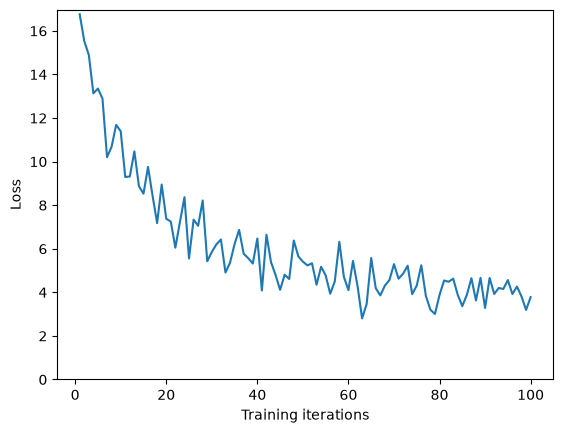

In [110]:
plt.plot(np.arange(1,len(loses)+1),loses)
plt.xlabel("Training iterations")
plt.ylabel("Loss")
plt.ylim(0, max(loses)+ 0.2)

Because we are working in batches, the computed gradient direction is not exact, but it is good enough to train the NN on repeated iterations. Its also just way cheaper to compute an approximate gradient and do more steps, rather that computing a perfect gradient. Using batches is an implementation of stochastic gradient descent (SGD).

### How to determine a good learning rate? -> Line search procedure

Make a *linear spacing* of the learning rate exponent. Then, iterate over those learning rates to compute a loss for each learning rate. The minimum in the plot of learning rate exponents versus loss reveals the approximate value of a good learning rate. After some training on the optimized learning rate, decay the learning rate on additional training iterations.

In [113]:
# Determine the learning rate
runs = 1000
lre = torch.linspace(-3, 0, runs)
lrs = 10**lre
loses = []

for k in range(runs):

    # Construct minibatch
    batch = torch.randint(0, X.shape[0], (32,))

    # Forward pass
    emb = C[X[batch]]
    h = torch.tanh(emb.view(emb.shape[0], 6) @ W1 + b1)
    logits = h @ W2 + b2
    # Compute loss
    loss = F.cross_entropy(logits, Y[batch])

    # Back pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # Update weights
    for p in parameters:
        p.data += -lrs[k] * p.grad 

    loses.append(loss.item())

print(loses)

[12.020796775817871, 13.54789924621582, 13.580416679382324, 11.884665489196777, 12.370222091674805, 13.311321258544922, 12.464367866516113, 11.706121444702148, 12.555476188659668, 11.804366111755371, 13.193432807922363, 13.67713451385498, 14.287345886230469, 12.867873191833496, 14.552556037902832, 11.977721214294434, 15.056696891784668, 13.60702896118164, 13.827940940856934, 13.410104751586914, 12.888374328613281, 15.515986442565918, 14.956290245056152, 14.069123268127441, 14.22499942779541, 13.641153335571289, 15.815969467163086, 12.778682708740234, 12.526542663574219, 14.689395904541016, 13.71142864227295, 11.615793228149414, 11.121009826660156, 15.751567840576172, 13.03753662109375, 14.397624969482422, 13.277556419372559, 14.135717391967773, 14.207613945007324, 13.187555313110352, 13.741925239562988, 16.04985809326172, 12.038330078125, 12.563265800476074, 14.150992393493652, 14.608271598815918, 13.709663391113281, 11.666044235229492, 13.848285675048828, 15.76438045501709, 13.2678861

(0.0, 16.249858093261718)

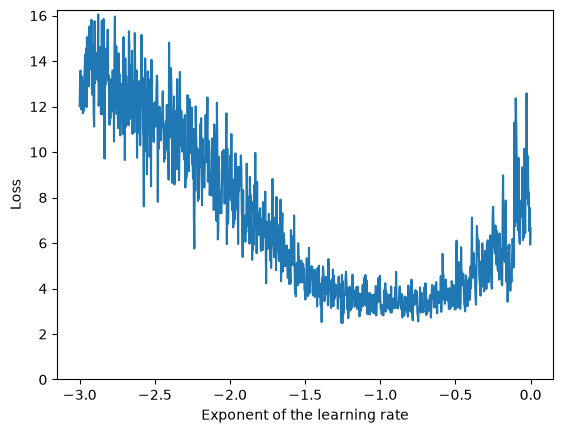

In [116]:
plt.plot(lre,loses)
plt.xlabel("Exponent of the learning rate")
plt.ylabel("Loss")
plt.ylim(0, max(loses)+ 0.2)

### How to prevent overfitting?
Split the data into: training (80%), dev/validation (10%), test (10%)

1. training - optimize parameters
2. validation - optimize hyper parameters
3. test - evaluate the model once, at the very end

The training and the validation set have the same loss? Then we are still underfitting and we can afford to add complexity to the training set. One way to do this is by increasing the number of neurons in the hidden layers.

In [123]:
# Build the dataset, with splitting of input sets

# Set the context length 
def build_dataset(words):
    blocksize = 3
    X, Y = [], []

    for w in words:
        context = [0] * blocksize
        for ch in w + ".":
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            # print("".join(itos[i] for i in context), "--->", itos[ix])
            context = context[1:] + [ix] 

    X = torch.tensor(X)
    Y = torch.tensor(Y)
    return X, Y

# shuffle up the input data, and split up the data
import random
random.seed(67)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xtest, Ytest = build_dataset(words[n2:])

In [147]:
# Initialize the NN params
g = torch.Generator().manual_seed(67)
C = torch.randn((27,2), generator=g)
W1 = torch.randn((6, 300))
b1 = torch.randn(300)
W2 = torch.randn((300, 27))
b2 = torch.randn(27)
parameters = [C, W1, b1, W2, b2]
for p in parameters:
    p.requires_grad = True

In [156]:
# Train the NN
# runs = 30000
# loses = []
# stepi = []

for k in range(runs):

    # Construct minibatch
    batch = torch.randint(0, Xtr.shape[0], (32,))

    # Forward pass
    emb = C[Xtr[batch]]
    h = torch.tanh(emb.view(emb.shape[0], 6) @ W1 + b1)
    logits = h @ W2 + b2
    # Compute loss
    loss = F.cross_entropy(logits, Ytr[batch])

    # Back pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # Update weights
    lr = 0.01
    for p in parameters:
        p.data += -lr * p.grad 

    loses.append(loss.item())
    stepi.append(k)

print(loses)

[22.922645568847656, 21.762359619140625, 21.01470375061035, 19.113786697387695, 20.25056266784668, 18.58974838256836, 18.167457580566406, 17.307584762573242, 17.982513427734375, 14.48210620880127, 13.294331550598145, 12.564927101135254, 15.244580268859863, 13.574817657470703, 11.261783599853516, 11.478684425354004, 12.22092056274414, 10.805773735046387, 11.057689666748047, 11.095199584960938, 13.000815391540527, 8.38147258758545, 8.422517776489258, 11.722112655639648, 9.208651542663574, 7.49886417388916, 12.306041717529297, 11.697139739990234, 7.933396339416504, 8.78775691986084, 8.481612205505371, 9.50618839263916, 6.924001216888428, 8.444670677185059, 8.002181053161621, 6.863750457763672, 6.2429118156433105, 9.05160140991211, 5.617469787597656, 7.070854663848877, 6.593990802764893, 6.109217643737793, 7.7180280685424805, 5.696902751922607, 5.901426315307617, 6.318415641784668, 9.322380065917969, 6.482580661773682, 5.193273067474365, 6.783281326293945, 7.717175483703613, 6.346417903900

(0.0, 23.122645568847656)

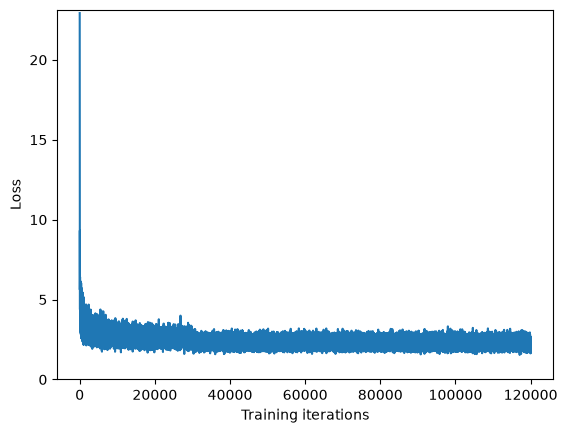

In [157]:
plt.plot(np.arange(1,len(loses)+1),loses)
plt.xlabel("Training iterations")
plt.ylabel("Loss")
plt.ylim(0, max(loses)+ 0.2)

In [159]:
# Evaluate on the dev set
emb = C[Xdev]
h = torch.tanh(emb.view(-1, 6) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Ydev)
loss

tensor(2.3147, grad_fn=<NllLossBackward0>)

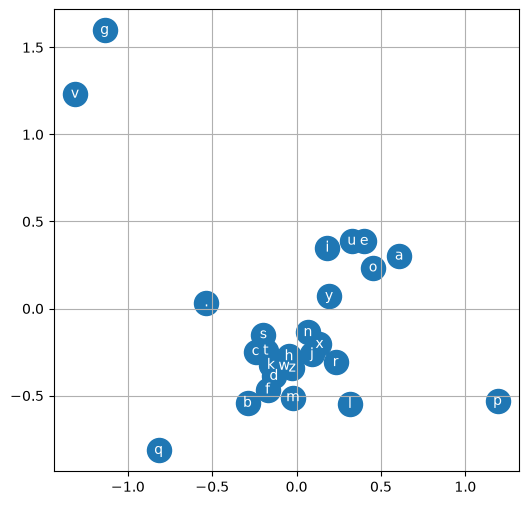

In [161]:
plt.figure(figsize=(6,6))
plt.scatter(C[:,0].data, C[:,1].data, s=300)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(), C[i, 1].item(), itos[i], 
        ha="center", va="center", color="white")
plt.grid("minor")

The network has learned to cluster the vowels together and some special characters are very distant from the main clusters. 

#### Now, improve the model by increasing the embedding vector

-> Use 10 dimensional embeddings

In [171]:
# Initialize the NN params
g = torch.Generator().manual_seed(67)
C = torch.randn((27,10), generator=g) # 10 D embeddings
W1 = torch.randn((30, 200))
b1 = torch.randn(200)
W2 = torch.randn((200, 27))
b2 = torch.randn(27)
parameters = [C, W1, b1, W2, b2]
for p in parameters:
    p.requires_grad = True

In [172]:
# Train the NN
runs = 50000
loses = []
stepi = []

In [184]:
for k in range(runs):

    # Construct minibatch
    batch = torch.randint(0, Xtr.shape[0], (32,))

    # Forward pass
    emb = C[Xtr[batch]]
    h = torch.tanh(emb.view(emb.shape[0], 30) @ W1 + b1)
    logits = h @ W2 + b2
    # Compute loss
    loss = F.cross_entropy(logits, Ytr[batch])

    # Back pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # Update weights
    lr = 0.005
    for p in parameters:
        p.data += -lr * p.grad 

    loses.append(loss.item())
    stepi.append(k)

print(loses[-1])

2.37768816947937


In [185]:
# Evaluate on the training set
emb = C[Xtr]
h = torch.tanh(emb.view(-1, 30) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Ytr)
loss

tensor(2.1494, grad_fn=<NllLossBackward0>)

In [186]:
# Evaluate on the dev set
emb = C[Xdev]
h = torch.tanh(emb.view(-1, 30) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Ydev)
loss

tensor(2.2011, grad_fn=<NllLossBackward0>)

1st round, dev loss = 2.3582, lr = 0.1  
2nd round, dev loss = 2.21, lr = 0.01  
3rd round, dev loss = 2.21, lr = 0.01  
4th rount, dev loss = 2.20, lr = 0.005  

At this point, the training loss improves marginally, and the dev loss is converged.

(0.0, 3.5547682909551135)

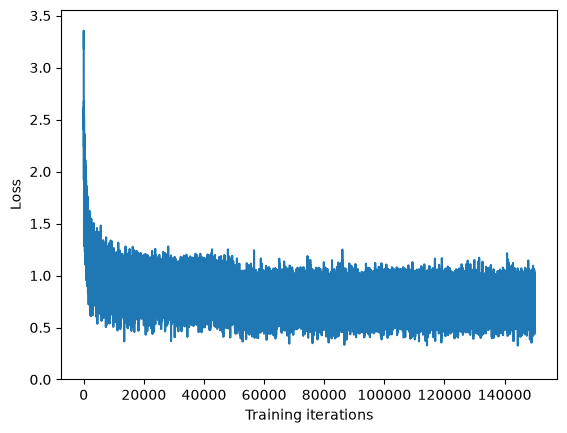

In [182]:
plt.plot(np.arange(1,len(loses)+1), np.log(loses))
plt.xlabel("Training iterations")
plt.ylabel("Loss")
plt.ylim(0, max(np.log(loses))+ 0.2)

In [193]:
# Sample form the model
g = torch.Generator().manual_seed(67)

for _ in range(15):
    out = []
    context = [0] * blocksize
    while True:
        emb = C[torch.tensor([context])]
        h = torch.tanh(emb.view(1, -1) @ W1 + b1)
        logits = h @ W2 + b2
        probs = F.softmax(logits, dim=1)
        ix = torch.multinomial(probs, num_samples=1, generator=g).item()
        context = context[1:] + [ix]
        out.append(ix)
        if ix == 0:
            break

    print("".join(itos[i] for i in out))

jalee.
muchante.
amis.
emona.
fusix.
jus.
amaryin.
narlelynn.
jatey.
emerran.
stin.
anayanne.
honilyannarfariet.
marcwie.
lovyn.
